# CodeBERT — Java Vulnerability CWE Detection

**Training data:** 90% of `vulnerability_fix_with_cwe.csv`
**Validation data:** 10% of `vulnerability_fix_with_cwe.csv`
**Test data:** `CodeLLMExp_java_only.csv` (held out, never seen during training)

**Split:** Stratified so every CWE class appears in train/validation.

> Set Runtime → T4 GPU before running.

## Step 1 — Install Dependencies

In [1]:
import re

def clean_code(code):
    if not isinstance(code, str):
        return ''
    # Remove code block fences (```python, ```java, ```, etc.)
    code = re.sub(r'```[\w]*\n?', '', code)
    code = re.sub(r'```', '', code)
    return code.strip()

def remove_java_imports(code):
    """
    Strips Java 'import ...;' and 'package ...;' statements from a code string.
    Also removes leading LLM preamble lines like
    'Here is the completed/modified Java code with a security vulnerability:'
    Leaves the rest of the code (including comments and blank lines inside methods) untouched.
    """
    if not isinstance(code, str):
        return code

    lines = code.split('\n')
    cleaned_lines = []
    for line in lines:
        stripped = line.strip()

        # Skip import statements (single-line, handles import static and wildcard imports too)
        if re.match(r'^import\s+(static\s+)?[\w.]+(\.\*)?\s*;', stripped):
            continue

        # Skip package declarations
        if re.match(r'^package\s+[\w.]+\s*;', stripped):
            continue

        # Skip common LLM preamble lines that leaked into the dataset
        if re.match(r'^(here is|below is|this is)\b.*\bjava code\b', stripped, re.IGNORECASE):
            continue

        cleaned_lines.append(line)

    result = '\n'.join(cleaned_lines)

    # Collapse resulting multiple blank lines left behind
    result = re.sub(r'\n{3,}', '\n\n', result)

    return result.strip()

def normalize_cwe(cwe):
    if not isinstance(cwe, str) or cwe.strip() == '':
        return 'Safe'
    cwe = cwe.strip()
    if cwe.lower() in ['fixed', 'safe', 'none', 'n/a', '']:
        return 'Safe'
    # Remove leading zeros: CWE-022 -> CWE-22
    match = re.match(r'^CWE-0*(\d+)$', cwe, re.IGNORECASE)
    if match:
        return f'CWE-{match.group(1)}'
    # If it's just a number, prepend 'CWE-'
    if re.match(r'^\d+$', cwe):
        return f'CWE-{int(cwe)}'
    return cwe.upper()


In [2]:
%%capture
!pip install transformers==4.40.0 datasets scikit-learn pandas numpy torch accelerate seaborn matplotlib tqdm

## Step 2 — Imports & GPU Setup

In [3]:
import os, re, json, gc, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
from tqdm import tqdm
from google.colab import drive

warnings.filterwarnings('ignore')
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Clear GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    free = (torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated()) / 1024**3
    print(f'Free VRAM: {free:.2f} GB')

Device: cuda
GPU: Tesla T4
Free VRAM: 14.56 GB


## Step 3 — Configuration

In [4]:
MODEL_NAME    = 'microsoft/codebert-base'
MAX_LEN       = 512
BATCH_SIZE    = 8
EPOCHS        = 3
LEARNING_RATE = 2e-5
WARMUP_RATIO  = 0.1
WEIGHT_DECAY  = 0.01

# ── Update this to your notebook folder in Drive ─────────────
NOTEBOOK_DIR = '/content/drive/MyDrive/Research/Experiment - 8/New'

TRAIN_CSV          = os.path.join(NOTEBOOK_DIR, 'vulnerability_fix_with_cwe.csv')
TEST_CSV           = os.path.join(NOTEBOOK_DIR, 'CodeLLMExp.csv')
MODEL_SAVE_PATH    = os.path.join(NOTEBOOK_DIR, 'codebert_cwe_model')
LABEL_ENCODER_PATH = os.path.join(NOTEBOOK_DIR, 'label_encoder.json')
CHECKPOINT_FILE    = os.path.join(NOTEBOOK_DIR, 'last_checkpoint.pt')

print('Config ready')

Config ready


## Step 4 — Mount Google Drive

In [5]:
drive.mount('/content/drive')

assert os.path.exists(TRAIN_CSV), f'Training file not found: {TRAIN_CSV}'
assert os.path.exists(TEST_CSV),  f'Test file not found: {TEST_CSV}'

print(f'Train CSV : {TRAIN_CSV}  ✅')
print(f'Test CSV  : {TEST_CSV}   ✅')

Mounted at /content/drive
Train CSV : /content/drive/MyDrive/Research/Experiment - 8/New/vulnerability_fix_with_cwe.csv  ✅
Test CSV  : /content/drive/MyDrive/Research/Experiment - 8/New/CodeLLMExp.csv   ✅


## Step 5 — Load CSVs & Build Train/Test Split

**Strategy:**
- Load `vulnerability_fix_with_cwe.csv`.
- Split `vulnerability_fix_with_cwe.csv` into 90% for training and 10% for validation, stratified by CWE.
- Load `CodeLLMExp_java_only.csv` entirely as the dedicated test set.
- Stratified splits ensure all CWE classes appear appropriately in train/validation.

In [6]:
# ── Load primary source CSV (vulnerability_fix_with_cwe.csv) ────────────────────────────────
# Columns: vulnerability_type, vulnerable_code, fixed_code, CWE
df_primary_source = pd.read_csv(TRAIN_CSV)
df_primary_source = df_primary_source[['vulnerable_code', 'CWE']].copy()
df_primary_source.columns = ['code_raw', 'cwe_raw']
df_primary_source['code_clean'] = df_primary_source['code_raw'].apply(clean_code)
df_primary_source['code_clean'] = df_primary_source['code_clean'].apply(remove_java_imports)   # <-- add this line
df_primary_source['cwe_norm']   = df_primary_source['cwe_raw'].apply(normalize_cwe)
df_primary_source = df_primary_source[df_primary_source['code_clean'].str.len() > 20].reset_index(drop=True)

print(f'Primary source samples (from {os.path.basename(TRAIN_CSV)}): {len(df_primary_source):,}')
print(f'Primary source CWE classes                        : {df_primary_source["cwe_norm"].nunique()}')

# ── Load dedicated test CSV (CodeLLMExp_java_only.csv) ─────────────────────────────────────────────
# Columns: language, cwe, severity, rate, code, label, ...
df_test = pd.read_csv(TEST_CSV)
df_test = df_test[['code', 'cwe']].copy()
df_test.columns = ['code_raw', 'cwe_raw']
df_test['code_clean'] = df_test['code_raw'].apply(clean_code)
df_test['code_clean'] = df_test['code_clean'].apply(remove_java_imports)
df_test['cwe_norm']   = df_test['cwe_raw'].apply(normalize_cwe)
df_test = df_test[df_test['code_clean'].str.len() > 10].reset_index(drop=True)

print(f'\nDedicated test samples (from {os.path.basename(TEST_CSV)})    : {len(df_test):,}')
print(f'Dedicated test CWE classes                          : {df_test["cwe_norm"].nunique()}')
print(f'\nDedicated test CWE distribution:')
print(df_test['cwe_norm'].value_counts())

Primary source samples (from vulnerability_fix_with_cwe.csv): 31,843
Primary source CWE classes                        : 5

Dedicated test samples (from CodeLLMExp.csv)    : 284
Dedicated test CWE classes                          : 5

Dedicated test CWE distribution:
cwe_norm
CWE-22     107
CWE-77      80
CWE-502     38
CWE-79      32
CWE-89      27
Name: count, dtype: int64


In [7]:
# ── Stratified 90/10 split of df_primary_source for training and validation ───────────────────────
# Handle rare classes in df_primary_source (need at least 2 samples for 90/10 split)
cwe_counts_primary = df_primary_source['cwe_norm'].value_counts()
rare_cwes_primary  = set(cwe_counts_primary[cwe_counts_primary < 2].index)
normal_cwes_primary = set(cwe_counts_primary[cwe_counts_primary >= 2].index)

df_primary_rare   = df_primary_source[df_primary_source['cwe_norm'].isin(rare_cwes_primary)]
df_primary_normal = df_primary_source[df_primary_source['cwe_norm'].isin(normal_cwes_primary)]

if rare_cwes_primary:
    print(f'Rare CWEs in primary source (all go to training): {sorted(rare_cwes_primary)}')

# Stratified split on normal CWEs
df_train, df_val = train_test_split(
    df_primary_normal,
    test_size    = 0.1, # 10% for validation
    random_state = SEED,
    stratify     = df_primary_normal['cwe_norm']
)

# Add rare CWEs entirely to training
df_train = pd.concat([df_train, df_primary_rare], ignore_index=True)

print(f'\nTraining set (90% of primary source): {len(df_train):,} samples')
print(f'Validation set (10% of primary source): {len(df_val):,} samples')
print(f'Dedicated Test set (100% of {os.path.basename(TEST_CSV)}): {len(df_test):,} samples') # df_test is already loaded

print(f'\nTraining set CWE distribution:')
print(df_train['cwe_norm'].value_counts())
print(f'\nValidation set CWE distribution:')
print(df_val['cwe_norm'].value_counts())


Training set (90% of primary source): 28,658 samples
Validation set (10% of primary source): 3,185 samples
Dedicated Test set (100% of CodeLLMExp.csv): 284 samples

Training set CWE distribution:
cwe_norm
CWE-79     8439
CWE-89     6567
CWE-77     6252
CWE-22     5850
CWE-502    1550
Name: count, dtype: int64

Validation set CWE distribution:
cwe_norm
CWE-79     938
CWE-89     730
CWE-77     695
CWE-22     650
CWE-502    172
Name: count, dtype: int64


In [8]:
# ── Summary of final dataset splits ─────────────────────────
print(f'Final Training Samples   : {len(df_train):,}')
print(f'Final Validation Samples : {len(df_val):,}')
print(f'Final Test Samples       : {len(df_test):,}')

print(f'\nTraining CWE distribution:')
print(df_train['cwe_norm'].value_counts())
print(f'\nValidation CWE distribution:')
print(df_val['cwe_norm'].value_counts())
print(f'\nTest CWE distribution (from {os.path.basename(TEST_CSV)}):')
print(df_test['cwe_norm'].value_counts())

Final Training Samples   : 28,658
Final Validation Samples : 3,185
Final Test Samples       : 284

Training CWE distribution:
cwe_norm
CWE-79     8439
CWE-89     6567
CWE-77     6252
CWE-22     5850
CWE-502    1550
Name: count, dtype: int64

Validation CWE distribution:
cwe_norm
CWE-79     938
CWE-89     730
CWE-77     695
CWE-22     650
CWE-502    172
Name: count, dtype: int64

Test CWE distribution (from CodeLLMExp.csv):
cwe_norm
CWE-22     107
CWE-77      80
CWE-502     38
CWE-79      32
CWE-89      27
Name: count, dtype: int64


## Step 6 — Label Encoding

In [9]:
# Build label set from ALL unique CWEs across both train and test
all_classes = sorted(set(df_train['cwe_norm'].unique()) | set(df_test['cwe_norm'].unique()))

le = LabelEncoder()
le.fit(all_classes)

df_train['label_enc'] = le.transform(df_train['cwe_norm'])
df_test['label_enc']  = le.transform(df_test['cwe_norm'])

NUM_CLASSES = len(le.classes_)
print(f'Total classes : {NUM_CLASSES}')
print(f'Classes       : {list(le.classes_)}')

label_map = {int(i): str(c) for i, c in enumerate(le.classes_)}
with open(LABEL_ENCODER_PATH, 'w') as f:
    json.dump(label_map, f, indent=2)
print(f'Label encoder saved')

Total classes : 5
Classes       : [np.str_('CWE-22'), np.str_('CWE-502'), np.str_('CWE-77'), np.str_('CWE-79'), np.str_('CWE-89')]
Label encoder saved


## Step 7 — Tokenizer

In [10]:
print(f'Loading tokenizer: {MODEL_NAME}')
tokenizer = RobertaTokenizer.from_pretrained(MODEL_NAME)
print('Tokenizer loaded')

Loading tokenizer: microsoft/codebert-base


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Tokenizer loaded


In [11]:
## Step 7.5 — Smart Truncation (Keep First + Last tokens)

def smart_truncate(code, tokenizer, max_len=512):
    """
    CodeBERT has a hard limit of 512 tokens.
    Default truncation keeps only the FIRST 512 tokens,
    which cuts off the vulnerable line if it appears late in the code.

    This function keeps:
    - First 128 tokens (imports, class definition)
    - Last 382 tokens (actual vulnerability logic)
    So the vulnerable line at the end is always preserved.
    """
    tokens = tokenizer.encode(code, add_special_tokens=False)

    if len(tokens) <= max_len - 2:   # fits fine, no truncation needed
        return tokenizer.decode(tokens)

    # Keep first 128 (class/import context) + last 382 (vulnerability logic)
    first_part = tokens[:128]
    last_part  = tokens[-(max_len - 128 - 2):]
    combined   = first_part + last_part

    return tokenizer.decode(combined)


# Apply to all splits
print('Applying smart truncation...')
df_train['code_clean'] = df_train['code_clean'].apply(lambda x: smart_truncate(x, tokenizer))
df_val['code_clean']   = df_val['code_clean'].apply(lambda x: smart_truncate(x, tokenizer))
df_test['code_clean']  = df_test['code_clean'].apply(lambda x: smart_truncate(x, tokenizer))
print(f'  Train : {len(df_train):,} samples done')
print(f'  Val   : {len(df_val):,} samples done')
print(f'  Test  : {len(df_test):,} samples done')

# Verify with the CWE-502 example
sample_code = """
import javax.servlet.http.HttpServletRequest;
import java.sql.*;
import org.yaml.snakeyaml.Yaml;
public class TemperatureHandler {
public void getTemperature(HttpServletRequest request) throws Exception {
String yamlPayload = request.getParameter("yamlData");
Yaml yaml = new Yaml();
Object data = yaml.load(yamlPayload);
}
}
"""
print('\nVerification on CWE-502 sample:')
print('Before:', sample_code[:80].replace('\n', ' '), '...')
print('After :', smart_truncate(sample_code, tokenizer)[:80].replace('\n', ' '), '...')
print('\nSmart truncation complete.')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (564 > 512). Running this sequence through the model will result in indexing errors


Applying smart truncation...
  Train : 28,658 samples done
  Val   : 3,185 samples done
  Test  : 284 samples done

Verification on CWE-502 sample:
Before:  import javax.servlet.http.HttpServletRequest; import java.sql.*; import org.yam ...
After :  import javax.servlet.http.HttpServletRequest; import java.sql.*; import org.yam ...

Smart truncation complete.


## Step 8 — Dataset Class

In [12]:
class JavaCWEDataset(Dataset):
    def __init__(self, codes, labels, tokenizer, max_len):
        self.codes     = codes
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.codes)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.codes[idx]),
            max_length     = self.max_len,
            padding        = 'max_length',
            truncation     = True,
            return_tensors = 'pt'
        )
        return {
            'input_ids'      : encoding['input_ids'].squeeze(0),
            'attention_mask' : encoding['attention_mask'].squeeze(0),
            'label'          : torch.tensor(int(self.labels[idx]), dtype=torch.long)
        }

print('Dataset class defined')

Dataset class defined


## Step 9 — Train/Validation Split & DataLoaders

In [13]:
df_val['label_enc'] = le.transform(df_val['cwe_norm'])

# The df_train, df_val, and df_test DataFrames are already prepared.
# No further splitting needed here for train/val.

# Remove classes with fewer than 1 sample (should be none after stratified split, but for safety)
labels_list_train = df_train['label_enc'].tolist()
label_counts_train = Counter(labels_list_train)
rare_classes_train = {cls for cls, cnt in label_counts_train.items() if cnt < 1}
if rare_classes_train:
    rare_names_train = le.inverse_transform(sorted(rare_classes_train))
    print(f'Removing {len(rare_classes_train)} rare class(es) from training: {list(rare_names_train)}')
    keep_train        = [l not in rare_classes_train for l in labels_list_train]
    df_train          = df_train[keep_train].reset_index(drop=True)

labels_list_val = df_val['label_enc'].tolist()
label_counts_val = Counter(labels_list_val)
rare_classes_val = {cls for cls, cnt in label_counts_val.items() if cnt < 1}
if rare_classes_val:
    rare_names_val = le.inverse_transform(sorted(rare_classes_val))
    print(f'Removing {len(rare_classes_val)} rare class(es) from validation: {list(rare_names_val)}')
    keep_val        = [l not in rare_classes_val for l in labels_list_val]
    df_val          = df_val[keep_val].reset_index(drop=True)

train_dataset = JavaCWEDataset(
    df_train['code_clean'].tolist(),
    df_train['label_enc'].tolist(),
    tokenizer, MAX_LEN
)
val_dataset   = JavaCWEDataset(
    df_val['code_clean'].tolist(),
    df_val['label_enc'].tolist(),
    tokenizer, MAX_LEN
)
test_dataset  = JavaCWEDataset(
    df_test['code_clean'].tolist(),
    df_test['label_enc'].tolist(),
    tokenizer, MAX_LEN
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train  : {len(train_dataset):,} samples  ({len(train_loader):,} batches)')
print(f'Val    : {len(val_dataset):,} samples  ({len(val_loader):,} batches)')
print(f'Test   : {len(test_dataset):,} samples  ({len(test_loader):,} batches)')

Train  : 28,658 samples  (3,583 batches)
Val    : 3,185 samples  (399 batches)
Test   : 284 samples  (36 batches)


## Step 10 — Load CodeBERT Model

In [14]:
torch.cuda.empty_cache()
gc.collect()

print(f'Loading {MODEL_NAME} with {NUM_CLASSES} output classes...')
model = RobertaForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = NUM_CLASSES
).to(DEVICE)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params    : {total:,}')
print(f'Trainable params: {trainable:,}')

Loading microsoft/codebert-base with 5 output classes...


config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: microsoft/codebert-base
Key                        | Status     | 
---------------------------+------------+-
pooler.dense.weight        | UNEXPECTED | 
pooler.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Total params    : 124,649,477
Trainable params: 124,649,477


## Step 11 — Training Setup & Checkpoint Resume

In [15]:
# Class weights for imbalanced CWEs
labels_list = labels_list_train + labels_list_val # Corrected: Define labels_list
actual_labels = sorted(set(labels_list))
class_weights = compute_class_weight(
    class_weight = 'balanced',
    classes      = np.array(actual_labels),
    y            = labels_list
)
full_weights = np.ones(NUM_CLASSES)
for i, cls in enumerate(actual_labels):
    full_weights[cls] = class_weights[i]

loss_fn = nn.CrossEntropyLoss(
    weight=torch.tensor(full_weights, dtype=torch.float).to(DEVICE)
)

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

# ── Resume from checkpoint if exists ─────────────────────────
start_epoch  = 1
best_val_acc = 0.0
history      = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

if os.path.exists(CHECKPOINT_FILE):
    print('Checkpoint found — resuming...')
    torch.cuda.empty_cache()
    gc.collect()

    # Load to CPU first to avoid OOM
    ckpt = torch.load(CHECKPOINT_FILE, map_location='cpu')

    # Extract everything before deleting
    saved_epoch  = ckpt['epoch']
    best_val_acc = ckpt['best_val_acc']
    history      = ckpt['history']
    model_state  = ckpt['model_state']
    del ckpt
    torch.cuda.empty_cache()
    gc.collect()

    # Load weights: CPU → load → GPU
    model.cpu()
    model.load_state_dict(model_state)
    del model_state
    torch.cuda.empty_cache()
    gc.collect()
    model.to(DEVICE)

    start_epoch = saved_epoch + 1
    print(f'  Resumed from epoch : {saved_epoch}')
    print(f'  Best val acc so far: {best_val_acc:.4f}')
    print(f'  Next epoch         : {start_epoch}')
else:
    print('No checkpoint found — starting from scratch')

# Always build optimizer and scheduler fresh (never load from checkpoint)
total_steps  = len(train_loader) * (EPOCHS - start_epoch + 1)
warmup_steps = int(total_steps * WARMUP_RATIO)

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = warmup_steps,
    num_training_steps = total_steps
)

print(f'\nRemaining steps : {total_steps:,}')
print(f'Warmup steps    : {warmup_steps:,}')
print(f'Starting epoch  : {start_epoch}')

Checkpoint found — resuming...
  Resumed from epoch : 2
  Best val acc so far: 0.9516
  Next epoch         : 3

Remaining steps : 3,583
Warmup steps    : 358
Starting epoch  : 3


## Step 12 — Training & Evaluation Functions

In [16]:
def train_epoch(model, loader, optimizer, scheduler, loss_fn, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    bar = tqdm(loader, desc='  Training', unit='batch')

    for batch in bar:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss    = loss_fn(outputs.logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

        if (bar.n + 1) % 100 == 0:
            torch.cuda.empty_cache()

        total_loss += loss.item()
        preds       = torch.argmax(outputs.logits, dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)
        bar.set_postfix(loss=f'{total_loss/(bar.n+1):.4f}', acc=f'{correct/total:.4f}')

    return total_loss / len(loader), correct / total


def evaluate(model, loader, loss_fn, device, desc='Evaluating'):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    bar = tqdm(loader, desc=f'  {desc}', unit='batch')

    with torch.no_grad():
        for batch in bar:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss    = loss_fn(outputs.logits, labels)

            total_loss += loss.item()
            preds       = torch.argmax(outputs.logits, dim=1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            bar.set_postfix(loss=f'{total_loss/(bar.n+1):.4f}', acc=f'{correct/total:.4f}')

    return total_loss / len(loader), correct / total, all_preds, all_labels

print('Functions defined')

Functions defined


## Step 13 — Fine-Tuning Loop

In [17]:
print('=' * 55)
print(f'  Fine-Tuning CodeBERT — {EPOCHS} Epochs')
print('=' * 55)

for epoch in range(start_epoch, EPOCHS + 1):
    print(f'\nEpoch {epoch}/{EPOCHS}')
    print('-' * 40)

    train_loss, train_acc = train_epoch(
        model, train_loader, optimizer, scheduler, loss_fn, DEVICE
    )
    val_loss, val_acc, _, _ = evaluate(
        model, val_loader, loss_fn, DEVICE, desc='Validating'
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f'  Train — Loss: {train_loss:.4f} | Acc: {train_acc:.4f}')
    print(f'  Val   — Loss: {val_loss:.4f} | Acc: {val_acc:.4f}')

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        model.save_pretrained(MODEL_SAVE_PATH)
        tokenizer.save_pretrained(MODEL_SAVE_PATH)
        print(f'  Best model saved (val_acc={best_val_acc:.4f})')

    # Save checkpoint after every epoch
    torch.save({
        'epoch'       : epoch,
        'model_state' : model.state_dict(),
        'best_val_acc': best_val_acc,
        'history'     : history
    }, CHECKPOINT_FILE)
    print(f'  Checkpoint saved → epoch {epoch}')

print(f'\nTraining complete. Best Val Accuracy: {best_val_acc:.4f}')

  Fine-Tuning CodeBERT — 3 Epochs

Epoch 3/3
----------------------------------------


  Training:  23%|██▎       | 813/3583 [11:47<40:11,  1.15batch/s, acc=0.9516, loss=0.1310]


KeyboardInterrupt: 

## Step 14 — Training Curves

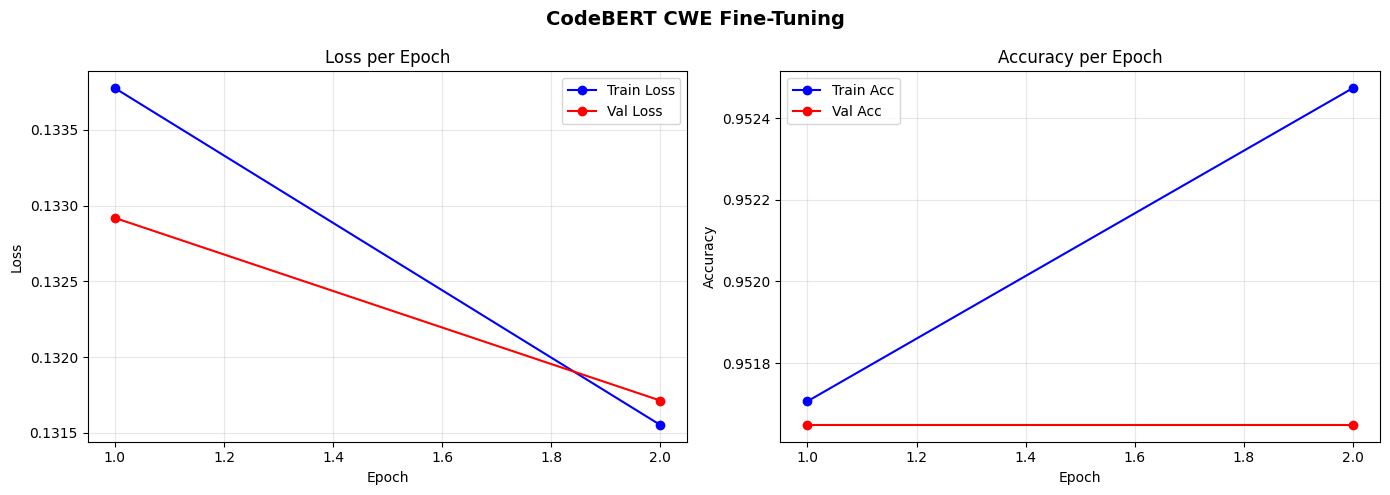

Saved: training_curves.png


In [18]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'],   'r-o', label='Val Loss')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train Acc')
axes[1].plot(epochs_range, history['val_acc'],   'r-o', label='Val Acc')
axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('CodeBERT CWE Fine-Tuning', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: training_curves.png')

## Step 15 — Test

In [19]:
print('Loading best saved model...')
torch.cuda.empty_cache()
gc.collect()

best_model = RobertaForSequenceClassification.from_pretrained(
    MODEL_SAVE_PATH,
    num_labels = NUM_CLASSES
).to(DEVICE)

print('Running inference on test set.')
test_loss, test_acc, test_preds_enc, test_labels_enc = evaluate(
    best_model, test_loader, loss_fn, DEVICE, desc='Testing'
)

test_preds_cwe  = le.inverse_transform(test_preds_enc)
test_actual_cwe = le.inverse_transform(test_labels_enc)

print(f'\nTest Loss     : {test_loss:.4f}')
print(f'Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)')

Loading best saved model...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Running inference on test set.


  Testing: 100%|██████████| 36/36 [00:09<00:00,  3.88batch/s, acc=0.7570, loss=2.1486]


Test Loss     : 2.1486
Test Accuracy : 0.7570  (75.70%)


## Step 16 — Accuracy Report

In [20]:
overall_acc = accuracy_score(test_actual_cwe, test_preds_cwe)
macro_f1    = f1_score(test_actual_cwe, test_preds_cwe, average='macro',    zero_division=0)
weighted_f1 = f1_score(test_actual_cwe, test_preds_cwe, average='weighted', zero_division=0)

print('=' * 55)
print('           TEST RESULTS SUMMARY')
print('=' * 55)
print(f'  Overall Accuracy  : {overall_acc*100:.2f}%')
print(f'  Macro F1          : {macro_f1:.4f}')
print(f'  Weighted F1       : {weighted_f1:.4f}')
print(f'  Test samples      : {len(test_preds_cwe):,}')
print('=' * 55)
print('\nPer-Class Report:')
print(classification_report(test_actual_cwe, test_preds_cwe, zero_division=0))

           TEST RESULTS SUMMARY
  Overall Accuracy  : 75.70%
  Macro F1          : 0.7392
  Weighted F1       : 0.7729
  Test samples      : 284

Per-Class Report:
              precision    recall  f1-score   support

      CWE-22       1.00      0.96      0.98       107
     CWE-502       1.00      0.47      0.64        38
      CWE-77       0.95      0.44      0.60        80
      CWE-79       0.33      1.00      0.49        32
      CWE-89       0.96      1.00      0.98        27

    accuracy                           0.76       284
   macro avg       0.85      0.77      0.74       284
weighted avg       0.91      0.76      0.77       284



## Step 17 — Confusion Matrix

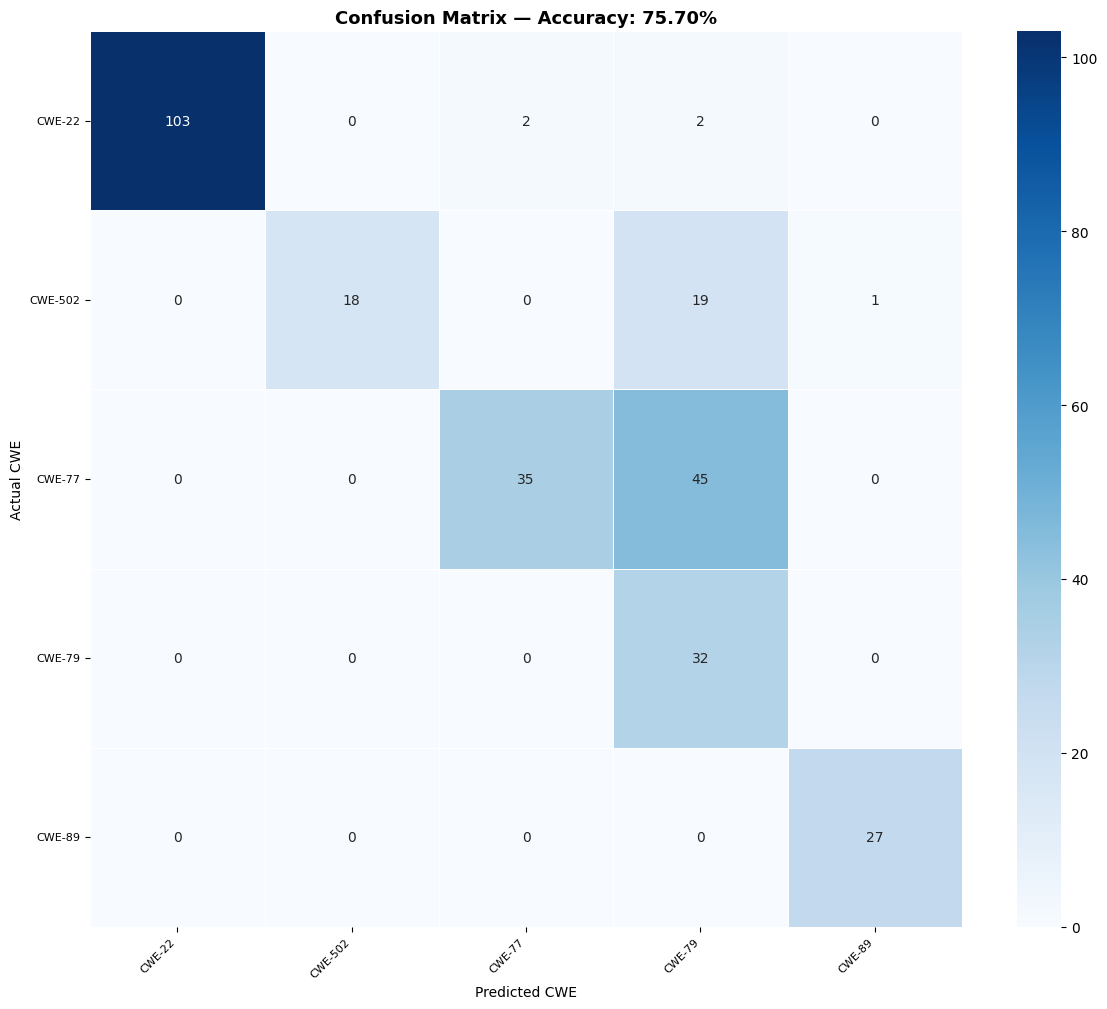

Saved: confusion_matrix.png


In [21]:
unique_labels = sorted(set(test_actual_cwe.tolist() + test_preds_cwe.tolist()))
cm = confusion_matrix(test_actual_cwe, test_preds_cwe, labels=unique_labels)

fig_size = max(12, len(unique_labels) * 0.6)
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_labels, yticklabels=unique_labels, linewidths=0.5)
plt.title(f'Confusion Matrix — Accuracy: {overall_acc*100:.2f}%', fontsize=13, fontweight='bold')
plt.xlabel('Predicted CWE')
plt.ylabel('Actual CWE')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrix.png')

## Step 18 — Per-CWE Accuracy Chart

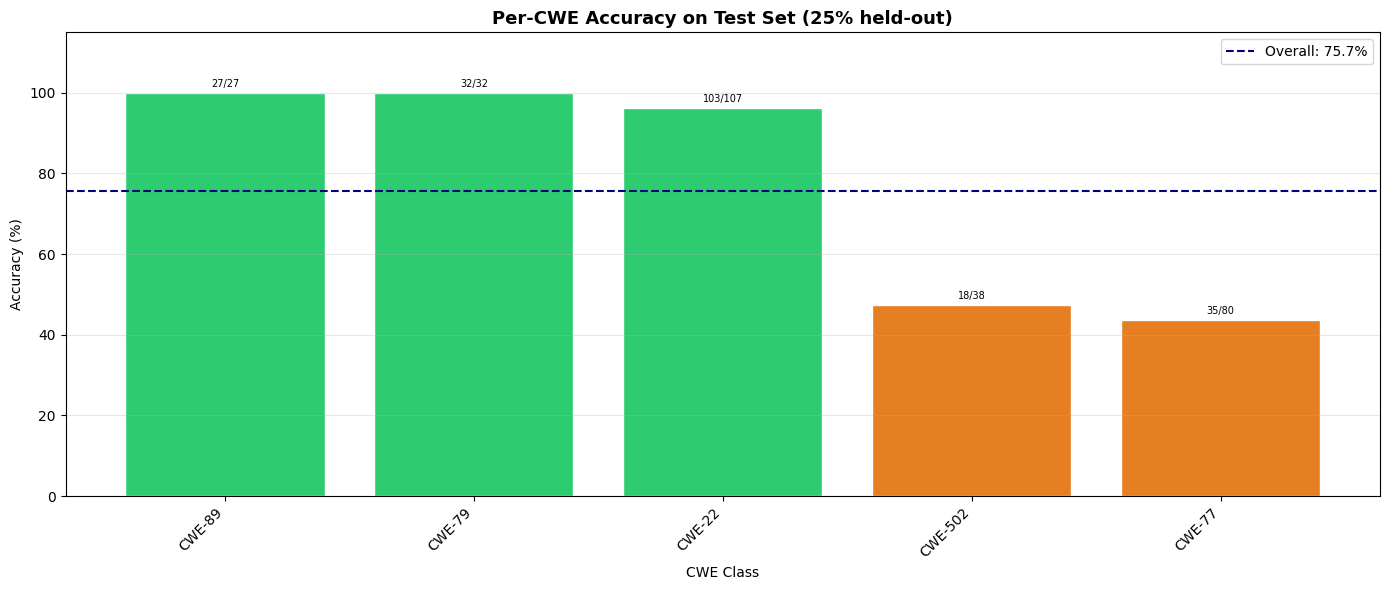

Saved: per_cwe_accuracy.png


In [22]:
results_df = pd.DataFrame({'actual': test_actual_cwe, 'predicted': test_preds_cwe})
results_df['correct'] = results_df['actual'] == results_df['predicted']

per_cwe = results_df.groupby('actual')['correct'].agg(['sum','count'])
per_cwe['accuracy'] = per_cwe['sum'] / per_cwe['count']
per_cwe = per_cwe.sort_values('accuracy', ascending=False)

colors = ['#2ecc71' if a >= 0.7 else '#e67e22' if a >= 0.4 else '#e74c3c' for a in per_cwe['accuracy']]

plt.figure(figsize=(14, 6))
bars = plt.bar(per_cwe.index, per_cwe['accuracy'] * 100, color=colors, edgecolor='white')
for bar, (_, row) in zip(bars, per_cwe.iterrows()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{int(row['sum'])}/{int(row['count'])}", ha='center', va='bottom', fontsize=7)

plt.axhline(y=overall_acc*100, color='navy', linestyle='--', label=f'Overall: {overall_acc*100:.1f}%')
plt.title('Per-CWE Accuracy on Test Set (25% held-out)', fontsize=13, fontweight='bold')
plt.xlabel('CWE Class')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 115)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'per_cwe_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: per_cwe_accuracy.png')

## Step 19 — Export Results CSV

In [23]:
output_df = pd.DataFrame({
    'code'          : df_test['code_clean'].values,
    'actual_cwe'    : test_actual_cwe,
    'predicted_cwe' : test_preds_cwe,
    'correct'       : (test_actual_cwe == test_preds_cwe)
})

RESULTS_PATH = os.path.join(NOTEBOOK_DIR, 'cwe_prediction_results.csv')
output_df.to_csv(RESULTS_PATH, index=False)

print(f'Results saved to Drive: {RESULTS_PATH}')
print(f'Total   : {len(output_df):,}')
print(f'Correct : {output_df["correct"].sum():,}')
print(f'Wrong   : {(~output_df["correct"]).sum():,}')
print(f'Accuracy: {output_df["correct"].mean()*100:.2f}%')

Results saved to Drive: /content/drive/MyDrive/Research/Experiment - 8/New/cwe_prediction_results.csv
Total   : 284
Correct : 215
Wrong   : 69
Accuracy: 75.70%


## Step 20 — Predict a Single Code Snippet

In [24]:
def predict_cwe(java_code, model, tokenizer, label_encoder, device, max_len=512):
    code = clean_code(java_code)
    enc  = tokenizer(code, max_length=max_len, padding='max_length',
                     truncation=True, return_tensors='pt')
    model.eval()
    with torch.no_grad():
        out   = model(input_ids=enc['input_ids'].to(device),
                      attention_mask=enc['attention_mask'].to(device))
        probs = torch.softmax(out.logits, dim=1).squeeze(0)
        idx   = torch.argmax(probs).item()
        cwe   = label_encoder.inverse_transform([idx])[0]
        conf  = probs[idx].item()
    top3 = [(label_encoder.inverse_transform([i])[0], probs[i].item())
            for i in torch.topk(probs, min(3, len(probs))).indices.tolist()]
    return cwe, conf, top3


sample = """
import java.sql.*;
public class LoginService {
    public ResultSet login(String user, String pass) throws Exception {
        Statement st = conn.createStatement();
        return st.executeQuery(
            "SELECT * FROM users WHERE name='" + user + "' AND pass='" + pass + "'"
        );
    }
}
"""

cwe, conf, top3 = predict_cwe(sample, best_model, tokenizer, le, DEVICE)

print('=' * 45)
print(f'  Predicted CWE : {cwe}')
print(f'  Confidence    : {conf*100:.2f}%')
print('  Top 3:')
for c, p in top3:
    print(f'    {c:15s} -> {p*100:.2f}%')
print('=' * 45)

  Predicted CWE : CWE-89
  Confidence    : 100.00%
  Top 3:
    CWE-89          -> 100.00%
    CWE-79          -> 0.00%
    CWE-77          -> 0.00%


In [25]:
## Step 21 — Confidence Calibration (Temperature Scaling)

import torch.optim as optim
from torch.nn import functional as F

class TemperatureScaler(nn.Module):
    """Wraps a model and learns a temperature T to scale logits."""
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, input_ids, attention_mask):
        with torch.no_grad():
            logits = self.model(input_ids=input_ids,
                                attention_mask=attention_mask).logits
        return logits / self.temperature

    def calibrate(self, val_loader, device, lr=0.01, max_iter=50):
        """Fit temperature on validation set using NLL loss."""
        self.to(device)
        optimizer = optim.LBFGS([self.temperature], lr=lr, max_iter=max_iter)
        all_logits, all_labels = [], []

        self.model.eval()
        with torch.no_grad():
            for batch in tqdm(val_loader, desc='  Collecting logits'):
                logits = self.model(
                    input_ids=batch['input_ids'].to(device),
                    attention_mask=batch['attention_mask'].to(device)
                ).logits
                all_logits.append(logits.cpu())
                all_labels.append(batch['label'])

        all_logits = torch.cat(all_logits).to(device)
        all_labels = torch.cat(all_labels).to(device)

        def eval_step():
            optimizer.zero_grad()
            loss = F.cross_entropy(all_logits / self.temperature, all_labels)
            loss.backward()
            return loss

        optimizer.step(eval_step)
        print(f'  Optimal temperature: {self.temperature.item():.4f}')
        return self

# Calibrate on validation set
print('Calibrating model confidence...')
calibrated_model = TemperatureScaler(best_model)
calibrated_model.calibrate(val_loader, DEVICE)

CALIBRATION_CONFIDENCE_THRESHOLD = 0.95  # Tune this based on your data
print(f'Confidence threshold for routing: {CALIBRATION_CONFIDENCE_THRESHOLD}')

Calibrating model confidence...


  Optimal temperature: 1.5525
Confidence threshold for routing: 0.95


In [48]:
## Step 22 — LLM Analysis (Hugging Face)

!pip install -q transformers accelerate bitsandbytes sentencepiece

import re, gc, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

LLM_MODEL = "Qwen/Qwen2.5-Coder-7B-Instruct"
# For DeepSeek use: "deepseek-ai/deepseek-coder-7b-instruct-v1.5"
LLM_NAME  = "Qwen2.5-Coder"           # for DeepSeek use: "DeepSeek-Coder"
USE_4BIT  = True                      # True = fits with CodeBERT on a T4. False = float16, same as zero-shot
GET_EXPLANATION = True                # False = classification only (faster)

# ── Load model ──────────────────────────────────────────────
gc.collect(); torch.cuda.empty_cache()

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)

if USE_4BIT:
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
    )
    llm_model = AutoModelForCausalLM.from_pretrained(
        LLM_MODEL, quantization_config=bnb_config, device_map="auto")
else:
    llm_model = AutoModelForCausalLM.from_pretrained(
        LLM_MODEL, torch_dtype=torch.float16, device_map="auto")

llm_model.eval()

CWE_NAMES = {
    "CWE-22" : "Path Traversal",
    "CWE-77" : "Command Injection",
    "CWE-502": "Deserialization of Untrusted Data",
    "CWE-79" : "Cross-Site Scripting (XSS)",
    "CWE-89" : "SQL Injection",
}

# Same prompt as the zero-shot experiment
ZS_PROMPT = """
You are an expert software security analyst specializing in Common Weakness Enumeration (CWE).

Your task is to classify the following vulnerable source code into exactly ONE of the following CWE categories:

- CWE-022: Path Traversal
- CWE-077: Command Injection
- CWE-502: Deserialization of Untrusted Data
- CWE-079: Cross-Site Scripting (XSS)
- CWE-089: SQL Injection

Instructions:
1. Carefully analyze the vulnerable source code.
2. Determine the primary security vulnerability present.
3. Map the vulnerability to the most appropriate CWE from the five categories listed above.
4. Reason internally before making your decision.
5. Return ONLY the CWE ID.

Rules:
- Return exactly one of:
  - CWE-022
  - CWE-077
  - CWE-502
  - CWE-079
  - CWE-089
- Do not provide any explanation.
- Do not include additional text.
- Do not output anything except the CWE ID.

Vulnerable Source Code:
{code}
"""

def _generate(prompt, max_new_tokens):
    messages = [{"role": "user", "content": prompt}]
    text = llm_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tokenizer(
        text, return_tensors="pt", truncation=True, max_length=4096
    ).to(llm_model.device)
    with torch.no_grad():
        out = llm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return llm_tokenizer.decode(
        out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()


def _explain(code, cwe):
    """Second call: explanation only. It cannot change the label."""
    prompt = f"""A Java function was classified as {cwe} ({CWE_NAMES[cwe]}).
Reply in exactly this format, one line each, and nothing else:
Explanation: <one or two sentences on why this code has this weakness>
Evidence: <the line or pattern in the code that shows it>
Fix: <one sentence on how to fix it>

Java code:
{code}"""
    try:
        txt = _generate(prompt, 200)
    except Exception:
        return "Not available.", "Not available.", "Not available."
    get = lambda k: (re.search(rf"{k}:\s*(.+)", txt) or [None, "Not available."])[1].strip()
    return get("Explanation"), get("Evidence"), get("Fix")


def llm_analyze_cwe(java_code: str, top3_predictions: list = None) -> dict:
    prompt = ZS_PROMPT.format(code=java_code)
    raw = None
    try:
        raw = _generate(prompt, 20)
        m = re.search(r"CWE-0*(22|77|502|79|89)\b", raw)
        if m:
            cwe = "CWE-" + m.group(1)            # matches le.classes_ / cwe_norm
            if GET_EXPLANATION:
                expl, evid, fix = _explain(java_code, cwe)
            else:
                expl, evid, fix = f"{LLM_NAME} classified this as {cwe}.", "n/a", "n/a"
            return {"cwe": cwe, "confidence": "n/a", "explanation": expl,
                    "verification": evid, "suggested_fix": fix,
                    "prompt_sent": prompt, "raw_llm_output": raw}
    except Exception as e:
        raw = f"LLM call failed: {e}"

    fallback = top3_predictions[0][0] if top3_predictions else "UNKNOWN"
    return {"cwe": fallback, "confidence": "low",
            "explanation": "LLM response could not be parsed.",
            "verification": "Manual review required.",
            "suggested_fix": "Manual review required.",
            "prompt_sent": prompt, "raw_llm_output": raw}

print(f'LLM analysis function defined — using {LLM_MODEL}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 22.6 MB/s eta 0:00:00


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM analysis function defined — using Qwen/Qwen2.5-Coder-7B-Instruct


In [49]:
## Step 23 — Hybrid Pipeline

def hybrid_predict(java_code: str,
                   calibrated_model,
                   tokenizer,
                   label_encoder,
                   device,
                   raw_code: str = None,
                   confidence_threshold: float = CALIBRATION_CONFIDENCE_THRESHOLD,
                   max_len: int = 512) -> dict:
    """
      1. CodeBERT predicts CWE + calibrated confidence (cleaned/truncated code)
      2. High confidence -> CodeBERT prediction is final
      3. Low confidence  -> LLM classifies the RAW, uncut code
    """
    code = clean_code(java_code)
    enc  = tokenizer(code, max_length=max_len, padding='max_length',
                     truncation=True, return_tensors='pt')

    calibrated_model.eval()
    with torch.no_grad():
        logits = calibrated_model(
            input_ids=enc['input_ids'].to(device),
            attention_mask=enc['attention_mask'].to(device)
        )
        probs = torch.softmax(logits, dim=1).squeeze(0)
        idx   = torch.argmax(probs).item()
        cwe   = label_encoder.inverse_transform([idx])[0]
        conf  = probs[idx].item()

    top3 = [
        (label_encoder.inverse_transform([i])[0], probs[i].item())
        for i in torch.topk(probs, min(3, len(probs))).indices.tolist()
    ]

    result = {
        'input_code'       : java_code,
        'codebert_cwe'     : cwe,
        'codebert_conf'    : conf,
        'top3_predictions' : top3,
        'routing'          : None,
        'final_cwe'        : None,
        'explanation'      : None,
        'verification'     : None,
        'suggested_fix'    : None,
        'llm_raw'          : None,
        'llm_input'        : None,
        'prompt_sent'      : None,
        'raw_llm_output'   : None,
    }

    if conf >= confidence_threshold:
        result['routing']       = 'codebert'
        result['final_cwe']     = cwe
        result['explanation']   = (f"CodeBERT classified this with {conf*100:.1f}% confidence as {cwe}. "
                                   f"High confidence, {LLM_NAME} analysis skipped.")
        result['verification']  = f"Top prediction: {cwe} ({conf*100:.1f}%)"
        result['suggested_fix'] = f"Address the {cwe} vulnerability in the code."
    else:
        result['routing'] = 'llm'
        print(f'  -> Low confidence ({conf*100:.1f}%), routing to {LLM_NAME}...')

        llm_input = raw_code if isinstance(raw_code, str) else java_code   # original, uncut code
        result['llm_input'] = llm_input

        llm_result = llm_analyze_cwe(llm_input, top3)
        result['llm_raw']        = llm_result
        result['final_cwe']      = llm_result.get('cwe', cwe)
        result['explanation']    = llm_result.get('explanation', '')
        result['verification']   = llm_result.get('verification', '')
        result['suggested_fix']  = llm_result.get('suggested_fix', '')
        result['prompt_sent']    = llm_result.get('prompt_sent')
        result['raw_llm_output'] = llm_result.get('raw_llm_output')

    return result


def print_pipeline_result(result: dict):
    print('=' * 60)
    print('  HYBRID CWE PREDICTION PIPELINE')
    print('=' * 60)
    print(f"  CodeBERT Prediction : {result['codebert_cwe']}")
    print(f"  CodeBERT Confidence : {result['codebert_conf']*100:.2f}%")
    routing_label = 'HIGH -> CodeBERT' if result['routing'] == 'codebert' else f'LOW -> {LLM_NAME} ({LLM_MODEL})'
    print(f"  Routing Decision    : {routing_label}")
    print(f"  -- Top 3 Predictions --")
    for c, p in result['top3_predictions']:
        print(f"     {c:15s} {p*100:.2f}%")
    print()
    print(f"  FINAL CWE           : {result['final_cwe']}")
    print(f"\n  EXPLANATION:\n  {result['explanation']}")
    print(f"\n  VERIFICATION:\n  {result['verification']}")
    print(f"\n  SUGGESTED FIX:\n  {result['suggested_fix']}")
    print('=' * 60)

print(f'Hybrid pipeline defined — using {LLM_NAME} for low-confidence routing.')

Hybrid pipeline defined — using Qwen2.5-Coder for low-confidence routing.


In [50]:
## Step 24 — Test the Hybrid Pipeline

sample_code = """
import java.sql.*;
public class LoginService {
    public ResultSet login(String user, String pass) throws Exception {
        Statement st = conn.createStatement();
        return st.executeQuery(
            "SELECT * FROM users WHERE name='" + user + "' AND pass='" + pass + "'"
        );
    }
}
"""

result = hybrid_predict(
    java_code=sample_code,
    calibrated_model=calibrated_model,
    tokenizer=tokenizer,
    label_encoder=le,
    device=DEVICE,
    confidence_threshold=CALIBRATION_CONFIDENCE_THRESHOLD
)

print_pipeline_result(result)

  HYBRID CWE PREDICTION PIPELINE
  CodeBERT Prediction : CWE-89
  CodeBERT Confidence : 100.00%
  Routing Decision    : HIGH -> CodeBERT
  -- Top 3 Predictions --
     CWE-89          100.00%
     CWE-79          0.00%
     CWE-77          0.00%

  FINAL CWE           : CWE-89

  EXPLANATION:
  CodeBERT classified this with 100.0% confidence as CWE-89. High confidence, Qwen2.5-Coder analysis skipped.

  VERIFICATION:
  Top prediction: CWE-89 (100.0%)

  SUGGESTED FIX:
  Address the CWE-89 vulnerability in the code.


In [51]:
## Step 25 — Batch Hybrid Pipeline Evaluation

def evaluate_hybrid_pipeline(df_test, calibrated_model, tokenizer, le,
                             DEVICE, threshold, sample_n=None):
    df_eval = df_test.head(sample_n).copy() if sample_n else df_test.copy()

    results = []
    codebert_routed, llm_routed = 0, 0

    for i, row in tqdm(df_eval.iterrows(), total=len(df_eval), desc='Hybrid Eval'):
        res = hybrid_predict(
            java_code=row['code_clean'],
            raw_code=row['code_raw'],
            calibrated_model=calibrated_model,
            tokenizer=tokenizer,
            label_encoder=le,
            device=DEVICE,
            confidence_threshold=threshold
        )
        results.append({
            'test_index'      : i,
            'actual_cwe'      : row['cwe_norm'],
            'codebert_cwe'    : res['codebert_cwe'],
            'codebert_conf'   : res['codebert_conf'],
            'top3'            : str(res['top3_predictions']),
            'routing'         : res['routing'],
            'final_cwe'       : res['final_cwe'],
            'correct'         : res['final_cwe'] == row['cwe_norm'],
            'code_sent_to_llm': res['llm_input'],
            'prompt_sent'     : res['prompt_sent'],
            'raw_llm_output'  : res['raw_llm_output'],
            'explanation'     : res['explanation'],
            'verification'    : res['verification'],
            'suggested_fix'   : res['suggested_fix'],
        })

        if res['routing'] == 'codebert':
            codebert_routed += 1
        else:
            llm_routed += 1

    results_df = pd.DataFrame(results)

    print('\n' + '=' * 55)
    print('  HYBRID PIPELINE EVALUATION RESULTS')
    print('=' * 55)
    print(f"  Total samples     : {len(results_df):,}")
    print(f"  CodeBERT routed   : {codebert_routed:,} ({codebert_routed/len(results_df)*100:.1f}%)")
    print(f"  LLM routed        : {llm_routed:,} ({llm_routed/len(results_df)*100:.1f}%)")
    print(f"  Overall Accuracy  : {results_df['correct'].mean()*100:.2f}%")

    cb  = results_df[results_df['routing'] == 'codebert']['correct'].mean()
    llm = results_df[results_df['routing'] == 'llm']['correct'].mean()
    print(f"  CodeBERT route acc: {cb*100:.2f}%")
    print(f"  LLM route acc     : {llm*100:.2f}%")

    failed = results_df['explanation'].astype(str).str.contains('could not be parsed').sum()
    print(f"  LLM parse failures: {failed}")
    print('=' * 55)

    return results_df

hybrid_results_df = evaluate_hybrid_pipeline(
    df_test, calibrated_model, tokenizer, le,
    DEVICE,
    threshold=CALIBRATION_CONFIDENCE_THRESHOLD,
)

hybrid_results_df.to_csv(
    os.path.join(NOTEBOOK_DIR, 'hybrid_pipeline_results.csv'), index=False
)
print('Saved: hybrid_pipeline_results.csv')

Hybrid Eval:   2%|▏         | 6/284 [00:00<00:15, 17.55it/s]

  -> Low confidence (82.3%), routing to Qwen2.5-Coder...


Hybrid Eval:   4%|▍         | 12/284 [00:11<05:05,  1.12s/it]

  -> Low confidence (54.1%), routing to Qwen2.5-Coder...


Hybrid Eval:  11%|█         | 30/284 [00:19<01:07,  3.77it/s]

...

  -> Low confidence (93.0%), routing to Qwen2.5-Coder...


Hybrid Eval:  97%|█████████▋| 276/284 [04:38<00:00,  9.49it/s]

  -> Low confidence (61.6%), routing to Qwen2.5-Coder...


Hybrid Eval: 100%|██████████| 284/284 [04:46<00:00,  1.01s/it]



  HYBRID PIPELINE EVALUATION RESULTS
  Total samples     : 284
  CodeBERT routed   : 250 (88.0%)
  LLM routed        : 34 (12.0%)
  Overall Accuracy  : 80.63%
  CodeBERT route acc: 78.80%
  LLM route acc     : 94.12%
  LLM parse failures: 0
Saved: hybrid_pipeline_results.csv


In [53]:
## Export: code sent to LLM, LLM prediction vs actual

llm_df = hybrid_results_df[hybrid_results_df['routing'] == 'llm'].copy()

# True if the answer came from the LLM. False if parsing failed and CodeBERT's label was used.
llm_df['llm_parsed_ok'] = ~llm_df['explanation'].astype(str).str.contains('could not be parsed')

export_df = pd.DataFrame({
    'test_index'      : llm_df['test_index'],
    'code_sent_to_llm': llm_df['code_sent_to_llm'],
    'actual_cwe'      : llm_df['actual_cwe'],
    'llm_prediction'  : llm_df['final_cwe'],
    'correct'         : llm_df['correct'],
    'llm_raw_output'  : llm_df['raw_llm_output'],
    'llm_parsed_ok'   : llm_df['llm_parsed_ok'],
    'codebert_cwe'    : llm_df['codebert_cwe'],
    'codebert_conf'   : llm_df['codebert_conf'],
})

out_path = os.path.join(NOTEBOOK_DIR, 'llm_code_vs_prediction.csv')
export_df.to_csv(out_path, index=False, encoding='utf-8-sig')   # utf-8-sig opens cleanly in Excel

print(f'Saved: {out_path}')
print(f'Rows: {len(export_df)} | Correct: {export_df["correct"].sum()} | '
      f'Parse failures: {(~export_df["llm_parsed_ok"]).sum()}')
export_df.head()

Saved: /content/drive/MyDrive/Research/Experiment - 8/New/llm_code_vs_prediction.csv
Rows: 34 | Correct: 32 | Parse failures: 0


,test_index,code_sent_to_llm,actual_cwe,llm_prediction,correct,llm_raw_output,llm_parsed_ok,codebert_cwe,codebert_conf
8,8,"import javax.servlet.http.*;\nimport java.io.IOException;\npublic class RestoreServlet extends HttpServlet {\nprotected void doPost(HttpServletRequest request, HttpServletResponse response)\nthrow...",CWE-77,CWE-77,True,CWE-077,True,CWE-79,0.823031
14,14,"import javax.servlet.http.*;\nimport java.io.IOException;\npublic class DatabaseRestoreServlet extends HttpServlet {\nprotected void doPost(HttpServletRequest request, HttpServletResponse response...",CWE-77,CWE-77,True,CWE-077,True,CWE-77,0.540502
32,32,"import javax.servlet.http.*;\nimport java.io.IOException;\npublic class DataMigrationServlet extends HttpServlet {\nprotected void doPost(HttpServletRequest request, HttpServletResponse response)\...",CWE-77,CWE-89,False,CWE-089,True,CWE-77,0.443809
36,36,import javax.servlet.http.*;\nimport java.io.IOException;\nimport java.util.Properties;\npublic class DatabaseRestoreServlet extends HttpServlet {\nprotected void doPost(HttpServletRequest request...,CWE-77,CWE-89,False,CWE-089,True,CWE-79,0.486257
38,38,import javax.servlet.http.*;\nimport java.io.IOException;\nimport java.util.logging.Logger;\npublic class RestoreServiceServlet extends HttpServlet {\nprivate static final Logger LOGGER = Logger.g...,CWE-77,CWE-77,True,CWE-077,True,CWE-79,0.910321


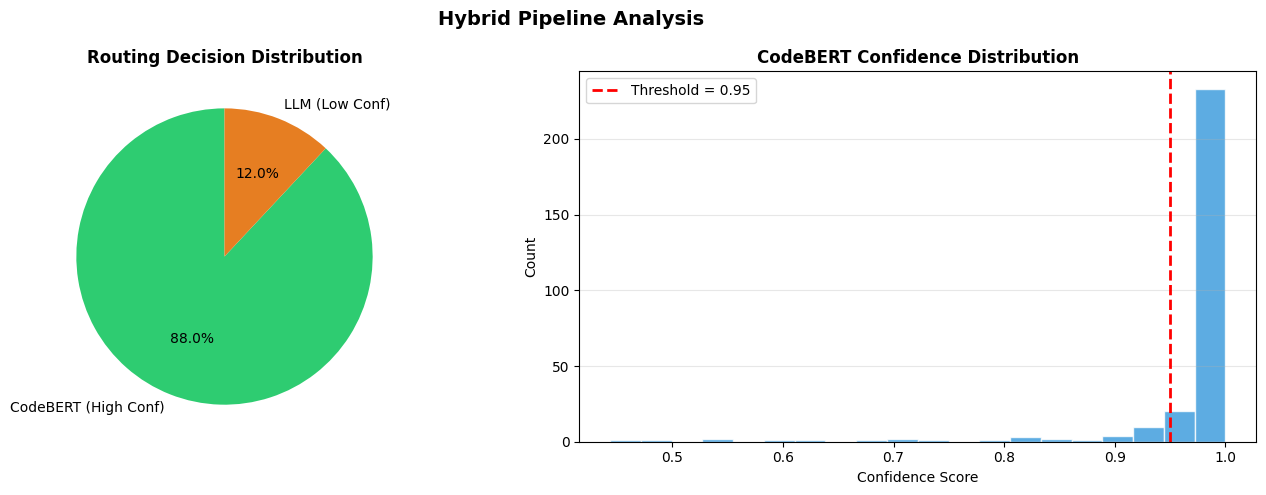

Saved: hybrid_pipeline_analysis.png


In [54]:
## Step 26 — Routing Distribution Plot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie: routing split
routing_counts = hybrid_results_df['routing'].value_counts()
axes[0].pie(routing_counts, labels=['CodeBERT (High Conf)', 'LLM (Low Conf)'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e67e22'], startangle=90)
axes[0].set_title('Routing Decision Distribution', fontweight='bold')

# Histogram: confidence distribution with threshold line
axes[1].hist(hybrid_results_df['codebert_conf'], bins=20, color='#3498db',
             edgecolor='white', alpha=0.8)
axes[1].axvline(x=CALIBRATION_CONFIDENCE_THRESHOLD, color='red',
                linestyle='--', linewidth=2,
                label=f'Threshold = {CALIBRATION_CONFIDENCE_THRESHOLD}')
axes[1].set_title('CodeBERT Confidence Distribution', fontweight='bold')
axes[1].set_xlabel('Confidence Score')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Hybrid Pipeline Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'hybrid_pipeline_analysis.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: hybrid_pipeline_analysis.png')

In [55]:
## Step — Inspect Test Set Samples

import pandas as pd
from google.colab import drive




# Set your save path
SAVE_PATH = '/content/drive/MyDrive/Research/Experiment - 8/New/test_set_inspection.csv'

# Collect all test set samples with their details
test_samples = []

for i in range(len(test_dataset)):
    sample        = test_dataset[i]
    label_encoded = sample['label'].item()
    label_name    = le.inverse_transform([label_encoded])[0]
    code_text     = df_test.iloc[i]['code_clean']

    test_samples.append({
        'index'        : i,
        'true_cwe'     : label_name,
        'label_encoded': label_encoded,
        'code_preview' : code_text
    })

# Convert to DataFrame
df_test_inspect = pd.DataFrame(test_samples)

# Show basic info
print('=' * 55)
print('  TEST SET OVERVIEW')
print('=' * 55)
print(f'  Total samples     : {len(df_test_inspect)}')
print(f'  Number of classes : {df_test_inspect["true_cwe"].nunique()}')
print()

# Show class distribution
print('  Class Distribution:')
dist = df_test_inspect['true_cwe'].value_counts()
for cwe, count in dist.items():
    print(f'    {cwe:15s} : {count} samples')
print('=' * 55)

# Show first 10 samples
print('\n  First 10 Samples:')
print(df_test_inspect[['index', 'true_cwe', 'code_preview']].head(10).to_string(index=False))

# Save to Google Drive
df_test_inspect.to_csv(SAVE_PATH, index=False)
print(f'\nSaved to Google Drive: {SAVE_PATH}')

  TEST SET OVERVIEW
  Total samples     : 284
  Number of classes : 5

  Class Distribution:
    CWE-22          : 107 samples
    CWE-77          : 80 samples
    CWE-502         : 38 samples
    CWE-79          : 32 samples
    CWE-89          : 27 samples

  First 10 Samples:
 index true_cwe                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        code_preview
     0   CWE